In [53]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
import seaborn as sns
from matplotlib.colors import LogNorm

# Intro

Still to do:
- merge målselva catchs and fluxes? Figure something out anyway
- calculate annual loads from monthly ones, just using resa linear interpolation. Plot.
- read in James' annual loads and compare. Plot.
- time period??
- Drop Pasvik
- Read in coastal drainage basins
- superimpose rid catchments onto them
- decide how to predict monthly & annual fluxes in rest of catches

From Heleen:

2.	Benchmark-1. James will provide the mean annual concentrations and loads for the RID rivers, which will be the internal benchmark.
3.	Benchmark-2. (for Glens paper, and maybe more usage elsewhere) 
    a.	RID elver (1990-2024) and Bielver (mostly 2004-2016), with a mix of modelled and empirical river discharge will be our Norsink Benchmark. 
    b.	The monthly and annual loads have been calculated using Resa3 (linear interpolation) (in the Norsink directory, including overview of missing data and sampling frequency etc); the OSPAR methodology should perhaps be slightly better (flow-weighted?). You will use the OSPAR (or other) method. There is a document with some method description. You will also make a map of catchments with river data.
    c.	The upscaling will probably be done (annual) using yield, for different drainage basins. The catchments bits to/from Sweden and Russia will be dealt with pragmatically
    d.	Extrapolation of data to start and end: DOC (TOC) is not present before 1999 in the main rivers. Bielver stop in 2016. So, whether 1990-2024 is the best period to consider or not, we need to think about (2000-2024?)
4.	The machine-learning will be presented in 3 weeks, where met-data and NVE data still need to be downloaded. Before that, you’ll magic around with various ML-methods to see if you can predict water chemistry (? Or only TOC?), and probably use various filters for the data (all; at least x data points, …).  A bit unclear to me if this also will be used to calculate loads, but I bet it will. Then we’ll have the benchmark to compare with. There are some good long-term monitoring data from Surelv that might be worth using together with other good datasets? (see Norsink).

Decide:
- All chem vars: RID and Bielver: Use Heleen's fluxes exported directly from RESA. Uses Q from best source (observed or modelled, depending on availability -> already in RESA). Just need to merge RID and bielver.
- Only TOC for now: Add in rivers from other good, long-term monitoring programs, where these are basically coastal drainage basins. Use Q from GTS API, already downloaded with vm data. Drop sites without long-term monitoring. Linear interpolation of chem data. Though in theory it would be quite easy to join in RESA-extracted data. But probably not as NIVA ID not preserved and lat/lon coords different...


In [71]:
out_folder = r"/home/jovyan/shared/common/norsink/niva_data_benchmark"

# RESA fluxes

## Monthly fluxes for national river monitoring rivers and bielver

Exported from RESA by Heleen. Calculated by linear interpolation of chem data to daily, and multiplication with discharge sourced either from observations (if available; assume they are area-scaled) or NVE simulated. Don't have metadata on catchment boundaries used.

In [4]:
resa_infolder = r"/home/jovyan/shared/common/norsink/niva_data_benchmark/from_resa_heleen"

rid_fname = "1990-2024 river element export standard national monitoring.xlsx"
bielv_fname = "RID Bielver 2004-2016 monthly element export.xlsx"

rid_siteinfo_fname = "1990-2025 river monitoring chemistry.xlsx"
bielv_siteinfo_fname = "RID Bielver 1990-2025 water chemistry.xlsx"

In [5]:
# Read in monthly fluxes calculated within RESA

# Main national river monitoring
rid_df = pd.read_excel(os.path.join(resa_infolder, rid_fname), sheet_name="data cleaned")
rid_df['Date'] = pd.to_datetime(rid_df['Date'])
rid_df['program'] = 'elveovervåking'

# Bielver
bielv_df = pd.read_excel(os.path.join(resa_infolder, bielv_fname), sheet_name="cleaned data")
bielv_df['Date'] = pd.to_datetime(bielv_df['Date'])
drop_cols = ['date-2']
bielv_df = bielv_df.drop(drop_cols, axis=1)
bielv_df['program'] = 'bielver'

# Merge
raw_resa_monthly_df = pd.concat([rid_df, bielv_df], axis=0)

# Reset date to 15th of month to centre it
raw_resa_monthly_df['Date'] = raw_resa_monthly_df['Date'] + pd.offsets.Day(14)

raw_resa_monthly_df

,Date,year,month,station_id,station_code,station_name,DOC_kg/km2,NH4-N_kg/km2,NO3-N_kg/km2,PO4-P_kg/km2,SO4_kg/km2,SiO2_kg/km2,TOC_kg/km2,TOTN_kg/km2,TOTP_kg/km2,TSM_kg/km2,flow_mm,program
0,1990-01-15,1990,1,40352,BUSEDRA,Drammenselva,NaN,NaN,7.156112,0.027581,NaN,NaN,NaN,10.474716,0.177920,33.326292,40.616629,elveovervåking
1,1990-02-15,1990,2,40352,BUSEDRA,Drammenselva,NaN,NaN,12.687276,0.080239,NaN,NaN,NaN,18.286681,0.300284,80.469826,44.429663,elveovervåking
2,1990-03-15,1990,3,40352,BUSEDRA,Drammenselva,NaN,NaN,13.602231,0.078194,NaN,NaN,NaN,20.539662,0.300325,72.745916,50.685843,elveovervåking
3,1990-04-15,1990,4,40352,BUSEDRA,Drammenselva,NaN,NaN,13.224302,0.071720,NaN,NaN,NaN,19.856412,0.263720,67.950202,50.475506,elveovervåking
4,1990-05-15,1990,5,40352,BUSEDRA,Drammenselva,NaN,NaN,12.733568,0.050533,NaN,NaN,NaN,21.471741,0.364993,100.119698,63.333034,elveovervåking
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4831,2016-08-15,2016,8,40397,VAGETOV,Tovdalselva,NaN,0.825630,2.395042,0.052217,NaN,113.945618,284.016403,14.920817,0.210737,91.309792,52.217310,bielver
4832,2016-09-15,2016,9,40397,VAGETOV,Tovdalselva,NaN,1.197380,1.484109,0.029137,NaN,63.582017,157.173180,9.083276,0.116550,51.657699,29.137425,bielver
4833,2016-10-15,2016,10,40397,VAGETOV,Tovdalselva,NaN,2.118209,1.858690,0.032245,NaN,70.362665,171.050645,10.917193,0.128979,58.608754,32.244760,bielver
4834,2016-11-15,2016,11,40397,VAGETOV,Tovdalselva,NaN,4.759610,4.120260,0.071039,NaN,155.017142,376.506485,24.153246,0.284156,129.290906,71.038959,bielver


In [6]:
# Deal with duplicates, i.e. where same station is in both bielver and national monitoring,
# then pick elveovervåking (likely QC'd more)
id_cols = [
    'Date', 'year', 'month',
    'station_id', 'station_code',
    'station_name', 'program'
]

flux_cols = [
    c for c in raw_resa_monthly_df.columns
    if c not in id_cols
    and pd.api.types.is_numeric_dtype(raw_resa_monthly_df[c])
]

# Duplicate check
dup_check = (
    raw_resa_monthly_df
    .groupby(['station_id', 'Date'])
    .filter(lambda x: len(x) > 1)
)

print("Number of duplicate site/months:", len(dup_check))
print("Number of sites with duplicates:", len(dup_check['station_id'].unique()))

# Remove duplicates
resa_monthly_df = raw_resa_monthly_df.copy()

# Assign priority
priority = {
    'elveovervåking': 0,
    'bielver': 1,
}

resa_monthly_df['priority'] = (
    resa_monthly_df['program'].map(priority)
)

# Keep elveovervåking in preference to bielver
resa_monthly_df = (
    resa_monthly_df
    .sort_values(['station_id', 'Date', 'priority'])
    .drop_duplicates(
        subset=['station_id', 'Date'],
        keep='first'
    )
    .drop(columns='priority')
    .reset_index(drop=True)
)

# Check it worked
assert (
    resa_monthly_df
    .groupby(['station_id', 'Date'])
    .size()
    .max()
) == 1

# Check for duplicate station-year-months. If none, then safe to proceed with reindexing to monthly and filling
dups = (
    resa_monthly_df
    .groupby(['station_id', 'year', 'month'])
    .size()
)

print(f"Duplicate station-year-months: {(dups > 1).sum()}")

resa_monthly_df.head()

Number of duplicate site/months: 936
Number of sites with duplicates: 3
Duplicate station-year-months: 0


,Date,year,month,station_id,station_code,station_name,DOC_kg/km2,NH4-N_kg/km2,NO3-N_kg/km2,PO4-P_kg/km2,SO4_kg/km2,SiO2_kg/km2,TOC_kg/km2,TOTN_kg/km2,TOTP_kg/km2,TSM_kg/km2,flow_mm,program
0,1990-01-15,1990,1,40352,BUSEDRA,Drammenselva,NaN,NaN,7.156112,0.027581,NaN,NaN,NaN,10.474716,0.177920,33.326292,40.616629,elveovervåking
1,1990-02-15,1990,2,40352,BUSEDRA,Drammenselva,NaN,NaN,12.687276,0.080239,NaN,NaN,NaN,18.286681,0.300284,80.469826,44.429663,elveovervåking
2,1990-03-15,1990,3,40352,BUSEDRA,Drammenselva,NaN,NaN,13.602231,0.078194,NaN,NaN,NaN,20.539662,0.300325,72.745916,50.685843,elveovervåking
3,1990-04-15,1990,4,40352,BUSEDRA,Drammenselva,NaN,NaN,13.224302,0.071720,NaN,NaN,NaN,19.856412,0.263720,67.950202,50.475506,elveovervåking
4,1990-05-15,1990,5,40352,BUSEDRA,Drammenselva,NaN,NaN,12.733568,0.050533,NaN,NaN,NaN,21.471741,0.364993,100.119698,63.333034,elveovervåking


In [7]:
# Check whether there are any missing months that need adding
month_counts = (
    resa_monthly_df
    .groupby(['station_id', 'year'])['month']
    .nunique()
)

print(month_counts.value_counts().sort_index())

month
12    1064
Name: count, dtype: int64


In [8]:
# Fill gaps

# There weren't any missing months. But if there were, this would deal with them (I think)
def complete_monthly_axis(g):

    full = pd.MultiIndex.from_product(
        [
            range(g['year'].min(), g['year'].max() + 1),
            range(1, 13)
        ],
        names=['year', 'month']
    )

    g = (
        g.set_index(['year', 'month'])
         .reindex(full)
         .reset_index()
    )

    g['station_id'] = g['station_id'].ffill().bfill()

    return g


# Reindex using complete month series
resa_full_monthly_df = (
    resa_monthly_df
    .groupby('station_id', group_keys=False)
    .apply(complete_monthly_axis)
)

# Add date (in case any new rows added, they will have NaN for date)
resa_full_monthly_df['Date'] = pd.to_datetime(
    dict(
        year=resa_full_monthly_df['year'],
        month=resa_full_monthly_df['month'],
        day=15
    )
)

# For QC
n_nan_before = resa_full_monthly_df[flux_cols].isna().sum()

# Interpolate any short gaps
resa_full_monthly_df[flux_cols] = (
    resa_full_monthly_df
    .groupby('station_id')[flux_cols]
    .transform(
        lambda x: x.interpolate(
            method='linear',
            limit=3,              # fill up to 3 consecutive months
            limit_area='inside'   # only interior gaps
        )
    )
)

# Forward or backward fill single months. N.B. this affects the start/end of the record,
# but also any gaps not filled by interpolation because they were too big. Could help complete
# a year though.
resa_full_monthly_df[flux_cols] = (
    resa_full_monthly_df
    .groupby('station_id')[flux_cols]
    .transform(
        lambda x: (
            x.ffill(limit=2)
             .bfill(limit=2)
        )
    )
)

# QC
before = len(resa_monthly_df)
after = len(resa_full_monthly_df)

print(f"Added {after-before:,} missing station-month rows")

# QC: number of NaNs filled
n_nan_after = resa_full_monthly_df[flux_cols].isna().sum()

nan_qc = pd.DataFrame({
    'before': n_nan_before,
    'after': n_nan_after
})

nan_qc['filled'] = nan_qc['before'] - nan_qc['after']

display(
    nan_qc
    .sort_values('filled', ascending=False)
)

print(f"Total NaNs before: {n_nan_before.sum():,}")
print(f"Total NaNs after:  {n_nan_after.sum():,}")
print(f"Total filled:      {(n_nan_before - n_nan_after).sum():,}")



Added 0 missing station-month rows


/tmp/ipykernel_2172/3560654771.py:29: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(complete_monthly_axis)


,before,after,filled
TOTN_kg/km2,3163,2999,164
SiO2_kg/km2,3824,3704,120
DOC_kg/km2,10524,10437,87
TOTP_kg/km2,2833,2746,87
TOC_kg/km2,2940,2856,84
SO4_kg/km2,11812,11772,40
NH4-N_kg/km2,2506,2466,40
NO3-N_kg/km2,2283,2259,24
PO4-P_kg/km2,2283,2259,24
TSM_kg/km2,2283,2259,24


Total NaNs before: 44,451
Total NaNs after:  43,757
Total filled:      694




In [9]:
# Quick visualisation of the time series

plot_df = resa_full_monthly_df

chem_col_dict = {
    'C': ['DOC_kg/km2', 'TOC_kg/km2'],
    # 'N': ['NH4-N_kg/km2', 'NO3-N_kg/km2', 'TOTN_kg/km2'],
    # 'P': ['PO4-P_kg/km2', 'TOTP_kg/km2'],
    # 'SO4': ['SO4_kg/km2'],
    # 'SiO2': ['SiO2_kg/km2'],
    # 'SS': ['TSM_kg/km2']
}

stations = sorted(plot_df['station_name'].unique())

for group, chem_cols in chem_col_dict.items():

    # Keep only cols that actually exist
    chem_cols = [c for c in chem_cols if c in plot_df.columns]

    if len(chem_cols) == 0:
        continue

    ncols = 1
    nrows = int(np.ceil(len(stations) / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(12 * ncols, 2.5 * nrows),
        sharex=True,
        sharey=True
        # constrained_layout=True
    )

    axes = np.atleast_1d(axes).flatten()
    for ax, station in zip(axes, stations):

        station_df = (
            plot_df.loc[plot_df['station_name'] == station]
            .sort_values('Date')
        )

        for col in chem_cols:
            ax.plot(
                station_df['Date'],
                station_df[col],
                lw=1,
                marker='o',
                markersize=2,
                label=col
            )

        ax.set_title(station, fontsize=9)
        ax.grid(alpha=0.3)
        ax.set_ylabel(f"{group} flux (kg/km2/month)")
        ax.legend()
        ax.set_ylim(ymin=0)

    # remove unused axes
    for ax in axes[len(stations):]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

## Annual areal fluxes

In [10]:
flux_cols = [c for c in resa_full_monthly_df.columns if c.endswith('_kg/km2')]

annual = []

for var in flux_cols:

    tmp = (
        resa_full_monthly_df.groupby(['station_code', 'year'])[var]
        .agg(
            annual_flux='sum',
            n_months='count'
        )
        .reset_index()
    )

    tmp['variable'] = var

    annual.append(
        tmp[['station_code', 'year', 'variable',
             'annual_flux', 'n_months']]
    )

resa_annual_df = pd.concat(annual, ignore_index=True)
resa_annual_df

,station_code,year,variable,annual_flux,n_months
0,AAGENID,2004,DOC_kg/km2,0.000000,0
1,AAGENID,2005,DOC_kg/km2,0.000000,0
2,AAGENID,2006,DOC_kg/km2,0.000000,0
3,AAGENID,2007,DOC_kg/km2,0.000000,0
4,AAGENID,2008,DOC_kg/km2,0.000000,0
...,...,...,...,...,...
10635,ØSTETIS,2012,TSM_kg/km2,1552.762087,12
10636,ØSTETIS,2013,TSM_kg/km2,1103.723164,12
10637,ØSTETIS,2014,TSM_kg/km2,3110.248429,12
10638,ØSTETIS,2015,TSM_kg/km2,2152.820476,12


In [12]:
incomplete_toc_yrs_df = resa_annual_df.loc[
    (resa_annual_df['n_months'] < 12)
    & (resa_annual_df['n_months'] > 0)
    & (resa_annual_df['variable'] == 'TOC_kg/km2')
]
print("Years with <12 months of TOC data (and > 0)", len(incomplete_toc_yrs_df))
print("Sites with incomplete years:", len(incomplete_toc_yrs_df['station_code'].unique()))

Years with <12 months of TOC data (and > 0) 24
Sites with incomplete years: 19


In [14]:
incomplete_toc_yrs_df['station_code'].unique()

array(['AAGEVEG', 'BUSEDRA', 'FINEALT', 'FINEPAS', 'FINETAN', 'HOREVOS',
       'MROEDRI', 'NOREVEF', 'OSLEALN', 'ROGEBJE', 'ROGEORR', 'ROGEVIK',
       'SFJENAU', 'STRENID', 'TELESKI', 'TROEMÅL2', 'VAGEOTR', 'VESENUM',
       'ØSTEGLO'], dtype=object)

In [ ]:
# # Take a look at Drammenwelva - monthly data before filling
# resa_monthly_df.loc[
#     (resa_monthly_df['station_code'] == 40352)
#     & (resa_monthly_df['year'] == 1993)
#     ]

In [ ]:
# # Take a look at Drammenwelva - monthly data after filling
# resa_full_monthly_df.loc[
#     (resa_full_monthly_df['station_code'] == 40352)
#     & (resa_full_monthly_df['year'] == 1993)
#     ]

Text(0.5, 0, 'Months available')

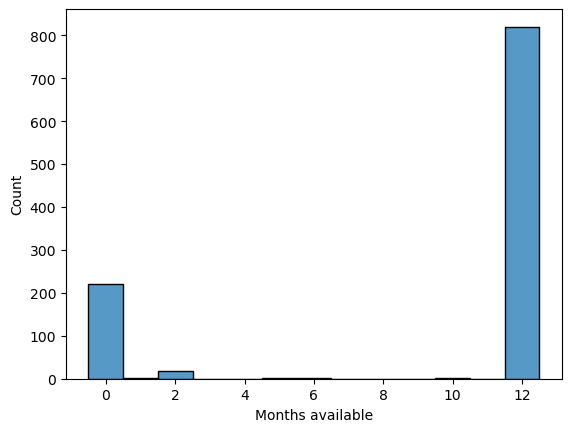

In [15]:
sns.histplot(
    data=resa_annual_df.loc[resa_annual_df['variable'] == 'TOC_kg/km2', :],
    x='n_months',
    discrete=True
)
plt.xlabel('Months available')

In [16]:
# Drop year-variable-site combos where have n_months < 12
if 'n_months' in resa_annual_df.columns:
    resa_annual_df = resa_annual_df.loc[resa_annual_df['n_months'] == 12]
    resa_annual_df = resa_annual_df.drop('n_months', axis=1)

resa_annual_df

,station_code,year,variable,annual_flux
40,AAGEVEG,2017,DOC_kg/km2,6521.812859
41,AAGEVEG,2018,DOC_kg/km2,4453.563021
42,AAGEVEG,2019,DOC_kg/km2,7038.603882
43,AAGEVEG,2020,DOC_kg/km2,6218.653517
44,AAGEVEG,2021,DOC_kg/km2,4055.361519
...,...,...,...,...
10635,ØSTETIS,2012,TSM_kg/km2,1552.762087
10636,ØSTETIS,2013,TSM_kg/km2,1103.723164
10637,ØSTETIS,2014,TSM_kg/km2,3110.248429
10638,ØSTETIS,2015,TSM_kg/km2,2152.820476


In [17]:
resa_annual_df.groupby('variable').describe()

year                                                           \
              count         mean       std     min      25%     50%      75%   
variable                                                                       
DOC_kg/km2    187.0  2019.315508  4.305776  1990.0  2017.50  2020.0  2022.00   
NH4-N_kg/km2  856.0  2010.398364  7.233221  1992.0  2006.00  2011.0  2015.00   
NO3-N_kg/km2  874.0  2009.988558  7.696854  1990.0  2006.00  2010.0  2015.00   
PO4-P_kg/km2  874.0  2009.988558  7.696854  1990.0  2006.00  2010.0  2015.00   
SO4_kg/km2     80.0  2022.500000  1.125088  2021.0  2021.75  2022.5  2023.25   
SiO2_kg/km2   745.0  2010.763758  6.318434  1995.0  2006.00  2010.0  2015.00   
TOC_kg/km2    820.0  2011.040244  6.688944  1990.0  2006.00  2011.0  2015.25   
TOTN_kg/km2   794.0  2009.030227  7.419282  1990.0  2005.00  2010.0  2014.00   
TOTP_kg/km2   829.0  2010.476478  7.597577  1990.0  2006.00  2011.0  2015.00   
TSM_kg/km2    874.0  2009.988558  7.696854  1990.0  2006.00  2010.0  2015.00   

                     annual_flux                                        \
                 max       count         mean          std         min   
variable                                                                 
DOC_kg/km2    2024.0       187.0  3048.713740  2320.207169  668.506977   
NH4-N_kg/km2  2024.0       856.0    14.097231    18.422826    0.696711   
NO3-N_kg/km2  2024.0       874.0   239.538404   363.784602    1.702224   
PO4-P_kg/km2  2024.0       874.0     5.798652    13.135160    0.358476   
SO4_kg/km2    2024.0        80.0  3265.667713  4486.632688  608.384816   
SiO2_kg/km2   2024.0       745.0  2292.200499  1132.374943  809.064032   
TOC_kg/km2    2024.0       820.0  2947.454441  2040.120899  531.549978   
TOTN_kg/km2   2024.0       794.0   437.843046   573.299977   30.706048   
TOTP_kg/km2   2024.0       829.0    12.775879    26.679808    0.903586   
TSM_kg/km2    2024.0       874.0  4443.079876  9499.734163  142.222918   

                                                                    
                      25%          50%          75%            max  
variable                                                            
DOC_kg/km2    1793.887543  2451.934920  3560.470306   15950.711826  
NH4-N_kg/km2     4.696873     8.779275    15.893110     172.686144  
NO3-N_kg/km2    75.213977   138.780990   215.267559    3510.220055  
PO4-P_kg/km2     1.428834     2.273786     4.277198     220.999799  
SO4_kg/km2    1252.559652  1858.713866  2745.647654   19918.325106  
SiO2_kg/km2   1622.914360  2042.060860  2587.153250   11452.742423  
TOC_kg/km2    1811.133209  2566.602164  3427.955965   17218.629954  
TOTN_kg/km2    191.074077   288.778108   407.555708    4164.436462  
TOTP_kg/km2      3.587590     5.855673     9.634309     267.201772  
TSM_kg/km2    1011.039550  1833.182440  3841.124940  136099.585211

# Annual fluxes calculated by James (OSPAR methodology)

In [18]:
infolder = r"/home/jovyan/shared/common/norsink/niva_data_benchmark/from_james"
osp_fname = "rid_concs_loads_summary_2024.xlsx"

osp_df = pd.read_excel(os.path.join(infolder, osp_fname), sheet_name="loads_flows_rid20_1990-2024")
osp_df

,station_id,station_code,station_name,old_rid_group,new_rid_group,ospar_region,year,mean_q_1000m3/day,Cd_tonnes,Cd_Est,...,NH4-N_tonnes,NH4-N_Est,Ni_tonnes,Ni_Est,SiO2_tonnes,SiO2_Est,Si_tonnes,Si_Est,TOC_tonnes,TOC_Est
0,29612,BUSEDRA,Drammenselva,rid_11,rid_20,SKAGERAK,1990,25891.134660,1.166017,0,...,175.664186,1,5.553244,1,19941.205828,1,12811.014340,1,29805.568171,1
1,29612,BUSEDRA,Drammenselva,rid_11,rid_20,SKAGERAK,1991,19274.318392,0.144235,0,...,130.756908,1,4.134041,1,14844.971273,1,9536.992973,1,16110.439028,0
2,29612,BUSEDRA,Drammenselva,rid_11,rid_20,SKAGERAK,1992,22209.901227,0.327690,0,...,163.311239,0,4.685295,0,17152.806199,1,11019.636830,1,23573.589162,0
3,29612,BUSEDRA,Drammenselva,rid_11,rid_20,SKAGERAK,1993,28155.888465,0.301564,0,...,140.697090,0,6.506741,0,21685.506430,1,13931.621600,1,28212.455887,0
4,29612,BUSEDRA,Drammenselva,rid_11,rid_20,SKAGERAK,1994,27384.945933,0.250260,0,...,149.020724,0,5.778524,1,21091.730842,1,13550.156826,1,30568.086091,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
730,38005,TROEMÅL2,Målselva v/gml E6-brua,NaN,rid_20,LOFOTEN-BARENTS SEA,2020,15794.699103,0.007090,0,...,16.386781,0,2.259160,0,14315.292201,1,7467.505590,0,18940.079596,0
731,38005,TROEMÅL2,Målselva v/gml E6-brua,NaN,rid_20,LOFOTEN-BARENTS SEA,2021,10192.812098,0.025483,0,...,28.626365,0,1.388208,0,7882.519055,0,6211.901468,0,5034.071049,0
732,38005,TROEMÅL2,Målselva v/gml E6-brua,NaN,rid_20,LOFOTEN-BARENTS SEA,2022,14298.851619,0.006010,0,...,54.886139,0,1.915236,0,11907.707598,0,5819.273109,0,5584.576093,0
733,38005,TROEMÅL2,Målselva v/gml E6-brua,NaN,rid_20,LOFOTEN-BARENTS SEA,2023,10295.596542,0.010107,0,...,53.444239,0,1.666109,0,8057.927271,0,3594.186636,0,4442.135210,0


# TOC ML training data matrix

Gives us:
- Activities, so have potential to filter shapefiles by activity name
- All the data needed to calculate fluxes for any catchment, if we're happy using the GTS API-derived runoff instead of observed for some rivers. E.g. for referanseelver.

In [32]:
data_dir = r"/home/jovyan/shared/common/norsink/vm_catchments_data"
vm_folder = os.path.join(data_dir, "training_data")
fname = f"training-data_TOC_full_min-samps-10.parquet"
fpath = os.path.join(vm_folder, fname)

# -------------
# Read data matrix
vm_df = pd.read_parquet(fpath)

# Parse dates
vm_df["date"] = pd.to_datetime(vm_df["date"])

vm_df.head()

,site_code,date,contractor,ActivityName,toc_mg_l,lon,lat,area_km2,vassomnr,slope_deg_mean,...,gts_runoff_daily_ecdf,gts_runoff_7d_sum,gts_runoff_30d_sum,gts_runoff_90d_sum,gts_precip_7d_sum,gts_precip_30d_sum,gts_precip_90d_sum,gts_temp_7d_mean,gts_temp_30d_mean,gts_temp_90d_mean
0,001-119928,2011-09-15,Eurofins (location unspecified),Tiltaksorientert overvåking,10.61,11.653745,59.47652,1008.505005,1,5.542838,...,0.968635,30.6543,68.8774,112.5280,57.5795,204.6595,454.8335,11.902286,13.116717,14.446294
1,001-119928,2012-10-09,Eurofins (location unspecified),Tiltaksorientert overvåking,9.96,11.653745,59.47652,1008.505005,1,5.542838,...,0.762379,8.7834,26.4669,62.0079,30.0655,130.1295,304.2480,6.048000,7.977317,11.737578
2,001-119928,2013-08-27,Eurofins (location unspecified),Tiltaksorientert overvåking,9.39,11.653745,59.47652,1008.505005,1,5.542838,...,0.135073,2.2584,9.9790,49.7646,0.2175,92.5385,215.6790,13.295429,14.572167,14.761300
3,001-119928,2014-08-19,Eurofins (location unspecified),Tiltaksorientert overvåking,7.46,11.653745,59.47652,1008.505005,1,5.542838,...,0.824009,8.0287,14.5404,45.9683,70.9985,160.0015,246.9360,12.480214,17.160600,15.755344
4,001-119928,2015-08-28,Eurofins (location unspecified),Tiltaksorientert overvåking,8.40,11.653745,59.47652,1008.505005,1,5.542838,...,0.583383,3.1422,14.4502,67.2611,44.9370,75.8890,251.2655,14.987500,14.430683,13.597400


In [33]:
# (drop the lake ones (økostor, økofersk) - not many sites anyway)
niva_activities = [
    "Elvetilførselsprogrammet",
    "Lokal overvåking av kalka vassdrag",
    "Tiltaksovervåking i kalkede laksevassdrag",
    "Elveovervåkingsprogrammet",
    "Referanseelver",
    "Lange tidsserier",
    "Forsuringsovervåking",
    "Elveserien. Kjemisk overvåking av norske vassdrag. ",
]

keep_cols = [
    "site_code",
    "date",
    "year",
    "contractor",
    "ActivityName",
    "toc_mg_l",
    "lon",
    "lat",
    "area_km2",
    "vassomnr",
    "t3_point_toc_tpyr",
    "gts_runoff_daily",
]

niva_vm_df = vm_df[keep_cols].loc[vm_df['ActivityName'].isin(niva_activities), :]
niva_vm_df

,site_code,date,year,contractor,ActivityName,toc_mg_l,lon,lat,area_km2,vassomnr,t3_point_toc_tpyr,gts_runoff_daily
842,001-38541,2004-03-23,2004,NIVA,Elvetilførselsprogrammet,7.5,11.444334,59.127828,1573.743139,1,36.867,4.0457
843,001-38541,2004-05-10,2004,NIVA,Elvetilførselsprogrammet,7.2,11.444334,59.127828,1573.743139,1,36.867,0.5608
844,001-38541,2004-08-09,2004,NIVA,Elvetilførselsprogrammet,7.4,11.444334,59.127828,1573.743139,1,36.867,0.2422
845,001-38541,2004-10-04,2004,NIVA,Elvetilførselsprogrammet,7.3,11.444334,59.127828,1573.743139,1,36.867,1.0583
848,001-38541,2005-02-14,2005,NIVA,Elvetilførselsprogrammet,7.9,11.444334,59.127828,1573.743139,1,36.867,0.5447
...,...,...,...,...,...,...,...,...,...,...,...,...
140658,313-39476,2020-10-19,2020,VestfoldLAB AS,Lokal overvåking av kalka vassdrag,20.5,11.700789,59.976306,10.246783,313,0.000,1.2818
140659,313-39476,2021-10-18,2021,VestfoldLAB AS,Lokal overvåking av kalka vassdrag,19.1,11.700789,59.976306,10.246783,313,0.000,0.7545
140660,313-39476,2022-10-18,2022,VestfoldLAB AS,Lokal overvåking av kalka vassdrag,28.6,11.700789,59.976306,10.246783,313,0.000,0.6545
140661,313-39476,2023-10-26,2023,Eurofins (Moss),Lokal overvåking av kalka vassdrag,23.0,11.700789,59.976306,10.246783,313,0.000,0.3364


In [34]:
rid_activities = [
     "Elvetilførselsprogrammet",
     "Elveovervåkingsprogrammet"
]
rid_vm_df = vm_df[keep_cols].loc[vm_df['ActivityName'].isin(rid_activities), :]
rid_vm_df

,site_code,date,year,contractor,ActivityName,toc_mg_l,lon,lat,area_km2,vassomnr,t3_point_toc_tpyr,gts_runoff_daily
842,001-38541,2004-03-23,2004,NIVA,Elvetilførselsprogrammet,7.5,11.444334,59.127828,1573.743139,1,36.867,4.0457
843,001-38541,2004-05-10,2004,NIVA,Elvetilførselsprogrammet,7.2,11.444334,59.127828,1573.743139,1,36.867,0.5608
844,001-38541,2004-08-09,2004,NIVA,Elvetilførselsprogrammet,7.4,11.444334,59.127828,1573.743139,1,36.867,0.2422
845,001-38541,2004-10-04,2004,NIVA,Elvetilførselsprogrammet,7.3,11.444334,59.127828,1573.743139,1,36.867,1.0583
848,001-38541,2005-02-14,2005,NIVA,Elvetilførselsprogrammet,7.9,11.444334,59.127828,1573.743139,1,36.867,0.5447
...,...,...,...,...,...,...,...,...,...,...,...,...
140615,311-90046,2020-08-03,2020,NIVA,Elveovervåkingsprogrammet,4.0,12.282350,61.289100,4406.921003,311,11.759,0.7955
140616,311-90046,2020-09-07,2020,NIVA,Elveovervåkingsprogrammet,3.1,12.282350,61.289100,4406.921003,311,11.759,0.3949
140617,311-90046,2020-10-05,2020,NIVA,Elveovervåkingsprogrammet,5.5,12.282350,61.289100,4406.921003,311,11.759,1.5288
140618,311-90046,2020-11-02,2020,NIVA,Elveovervåkingsprogrammet,7.4,12.282350,61.289100,4406.921003,311,11.759,3.9712


# Shapefiles for the RID rivers

## Read in catchment shapefiles delineated for all vannmiljø monitoring points

Has:
- Metadata on number of samples. Useful for filtering.
- Corrected lat and lon (there is a QC step between our sampling coordinates and the vannmiljø ones...)
- Catchment polygons

In [28]:
vm_catchs_fpath = r"/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/catchments_vm-rivs-quant-oc_v3-full.gpkg"
vm_catchs_gdf = gpd.read_file(vm_catchs_fpath)
vm_catchs_gdf.head()

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,geometry
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,1008.505005,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,1009.065359,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,6.702626,"POLYGON ((298520 6555300, 298640 6555300, 2986..."
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,15.372746,"POLYGON ((290660 6567260, 290680 6567260, 2906..."
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,42.290760,"POLYGON ((305560 6548480, 305560 6548500, 3055..."


## Make df of unique monitoring points in RESA-derived RID fluxes

In [29]:
# To join to vm catchment shapefiles and data, need lat and lon
# This is available in site info sheet downloaded by Heleen

rid_siteinfo = pd.read_excel(os.path.join(resa_infolder, rid_siteinfo_fname), sheet_name="Site info")
rid_siteinfo = rid_siteinfo.set_index('Station id')

bielv_siteinfo = pd.read_excel(os.path.join(resa_infolder, bielv_siteinfo_fname), sheet_name="Site info")
bielv_siteinfo = bielv_siteinfo.set_index('Station id')

# Concatenate RID and bielver site info
resa_siteinfo_df = pd.concat([rid_siteinfo, bielv_siteinfo], axis=0)

# # Take a look at duplicate station ids. Find there are 4 rows for each of station_id = 40387 and 40391
# dups = resa_siteinfo_df.index[resa_siteinfo_df.index.duplicated(keep=False)]
# resa_siteinfo_df.loc[dups].sort_index()

# Drop duplicates, keeping rows that include station_code where present (not in bielver file)
resa_siteinfo_df = (
    resa_siteinfo_df
    .reset_index()
    .sort_values('station_code', na_position='last')
    .drop_duplicates(subset='Station id', keep='first')
    .set_index('Station id')
)

resa_siteinfo_df.tail()

,station_code,station_name,Fylke,Discharge station name,Fylke.1,Fylkenummer,Kommunenavn,Kommunenummer,Naturvernform,VannforekomstID,VannforekomstNavn,Vannregionens EU-CD,Vassdragsnummer,Catchment area,Longitude,Latitude,Type,RBD
Station id,,,,,,,,,,,,,,,,,,
40393,NaN,NaN,Telemark,NVE Modellert Felt 17,NaN,40,Kragerø,4014,NaN,017-224-R,Kammerfosselva,NO5102,Kragerøvassdraget/bamble og Kragerø kommuner,1200.0,9.353998,58.875994,River,Ukjent
40394,NaN,NaN,Troms,NVE Modellert Felt 196,NaN,55,Målselv,5524,NaN,196-250-R,Nedre Barduelv,NO1104,Målselvvassdraget/Malangen,2906.0,18.594981,69.042997,River,Ukjent
40396,NaN,NaN,Agder,NVE Modellert Felt 25,NaN,42,Kvinesdal,4227,NaN,025-431-R,Litleåne Galdalsvann - Kvina,NO5103,Kvina/Fedafjorden,1140.0,6.969987,58.319995,River,Ukjent
40397,NaN,NaN,Agder,NVE Modellert Felt 20,NaN,42,Kristiansand,4204,NaN,020-391-R,Topdalselva Flakksvann - Topdalsfjorden bekkefelt,NO5103,Tovdalsvassdraget/Lillesand kommune,1854.0,8.114860,58.215990,River,NaN
66400,NaN,NaN,Rogaland,NaN,NaN,11,Sauda,1135,NaN,037-8-R,Nordelva,NO5104,Saudavassdraget/Saudafjorden og Sandsfjorden nord,NaN,6.357781,59.649962,River,NaN


In [30]:
# Not all of the sites in resa_siteinfo_df actually have fluxes data (e.g. no Q data,...)
# And the siteinfo_df is also missing some names and station codes. So use the flux df as starting point
# for site metadata, and add lat and lon from resa_siteinfo_df

# So pick out unique sites that are in the flux df
site_id_cols = ['station_code', 'station_name', 'station_id']#, 'program']  # (3 sites were bielver and then beceame main rivers)
resa_sites_df = resa_full_monthly_df[site_id_cols].drop_duplicates().reset_index(drop=True)

# Then add lat and lon
resa_sites_df = resa_sites_df.set_index('station_id').join(resa_siteinfo_df[['Latitude', 'Longitude']])

# Fill NaNs in lat and lon for Målselv (get manually from Vannmiljø)
resa_sites_df.loc[40395, ['Latitude']] = 69.13887
resa_sites_df.loc[40395, ['Longitude']] = 18.60298

resa_sites_df = resa_sites_df.reset_index()

# resa_sites_df.to_csv(os.path.join(outfolder, "resa_sites_codes.csv"))
print(len(resa_sites_df))
resa_sites_df.head()

48


,station_id,station_code,station_name,Latitude,Longitude
0,40352,BUSEDRA,Drammenselva,59.752576,10.007898
1,40353,TELESKI,Skienselva,59.203230,9.606396
2,40354,VAGEOTR,Otra,58.184772,7.958165
3,40355,VESENUM,Numedalslågen,59.101283,10.070949
4,40356,ØSTEGLO,Glomma ved Sarpsfoss,59.279802,11.134112


## Matching RESA IDs to Vannmiljø IDs

In [35]:
# Try to reduce number of candidate vannmiljø shapefiles, as matching isn't going to be totally straightforward
highn_vm_catch_gdf = vm_catchs_gdf.loc[vm_catchs_gdf['n_samples'] >= 10].copy()
print(len(highn_vm_catch_gdf))

rid_vm_catch_gdf = vm_catchs_gdf.loc[vm_catchs_gdf['site_code'].isin(rid_vm_df['site_code'].unique())].copy()
print(len(rid_vm_catch_gdf))

rid_vm_catch_gdf.head()

2558
131


,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,geometry
12,001-38541,11.444334,59.127828,38541,"Tista, utløp Femsjøen (FEMU)",1990,2025,35.7,841,23.56,1573.743139,"POLYGON ((315400 6600440, 315320 6600440, 3153..."
208,002-113858,11.364790,60.206990,113858,Vorma nedstræms Svanfoss,2022,2024,2.5,31,12.44,4.806200,"POLYGON ((296400 6680940, 296520 6680940, 2965..."
443,002-30582,11.356140,60.214057,30582,Vorma ved Svanfoss (V3),1989,2020,31.1,511,16.42,17457.048830,"POLYGON ((169260 6810900, 169280 6810900, 1692..."
444,002-30583,11.080568,60.133023,30583,Leira ved Kråkfossen,1996,2025,29.8,794,26.67,432.747148,"POLYGON ((264980 6707520, 265040 6707520, 2650..."
485,002-38516,11.134294,59.279465,38516,Glomma ved Sarpsfoss,1990,2024,34.7,539,15.55,41688.901865,"POLYGON ((224740 6795540, 224720 6795540, 2247..."


In [36]:
# Now need to add Vannmiljø ID to link to catchment shapefile
# See that code is no use, name is no use. Lat/lon the only hope

# There is a lot of difference in coordinates between the same site in RESA & VM,
# so need to only round to 1 d.p. for matching to work (at least a bit).
resa_sites_df['lat_r'] = resa_sites_df['Latitude'].round(1)
resa_sites_df['lon_r'] = resa_sites_df['Longitude'].round(1)

rid_vm_catch_gdf['lat_r'] = rid_vm_catch_gdf['lat'].round(1)
rid_vm_catch_gdf['lon_r'] = rid_vm_catch_gdf['lon'].round(1)

# Add prefixes to (non-join) cols to show origin, then merge
resa_sites_df = resa_sites_df.rename(
    columns={c: f'resa_{c}' for c in resa_sites_df.columns
             if c not in ['lat_r', 'lon_r']}
)

rid_vm_catch_gdf = rid_vm_catch_gdf.rename(
    columns={c: f'vm_{c}' for c in rid_vm_catch_gdf.columns
             if c not in ['lat_r', 'lon_r', 'geometry']}
)

# Merge to find candidate matching catchment boundaries per resa_station_id
matches = resa_sites_df.merge(
    rid_vm_catch_gdf,
    on=['lat_r', 'lon_r'],
    how='left'
)

rename_dict = {
    'resa_Latitude': 'resa_lat',
    'resa_Longitude': 'resa_lon',
    'resa_station_name': 'resa_name',
    'vm_Name': 'vm_name'
}

matches = matches.rename(rename_dict, axis=1)

# How many ambiguous matches do we have? i.e. multiple potential catchment polygons per resa station id
dups = matches.groupby('resa_station_id').size()
print(f"Sites with >1 match: {(dups > 1).sum()}")

# Inspect them
matches.loc[
    matches['resa_station_id'].isin(dups[dups > 1].index), :
].sort_values(['resa_station_id', 'vm_area_km2'])

Sites with >1 match: 5


,resa_station_id,resa_station_code,resa_name,resa_lat,resa_lon,lat_r,lon_r,vm_site_code,vm_lon,vm_lat,vm_site_id,vm_name,vm_start_year,vm_end_year,vm_n_years,vm_n_samples,vm_av_freq,vm_area_km2,geometry
4,40355,VESENUM,Numedalslågen,59.101283,10.070949,59.1,10.1,015-90017,10.070865,59.101239,90017.0,Numedalslågen ved Seierstad,2007.0,2024.0,17.7,205.0,11.59,5518.785674,"POLYGON ((188460 6604960, 188460 6604980, 1884..."
3,40355,VESENUM,Numedalslågen,59.101283,10.070949,59.1,10.1,015-38515,10.068150,59.086049,38515.0,Numedalslågen ved Bommestad (E18),1999.0,2024.0,25.7,202.0,7.85,5525.306956,"POLYGON ((188460 6604960, 188460 6604980, 1884..."
8,40358,FINEALT,Altaelva,69.930125,23.261237,69.9,23.3,212-90004,23.291971,69.874581,90004.0,Altaelva ved Øvre Stengelse,2017.0,2023.0,6.5,31.0,12.00,6348.172748,"POLYGON ((824660 7730040, 824680 7730040, 8246..."
7,40358,FINEALT,Altaelva,69.930125,23.261237,69.9,23.3,212-38518,23.284250,69.900959,38518.0,Altaelva ved Jorra,1991.0,2024.0,33.5,300.0,8.96,7324.235101,"POLYGON ((792620 7682980, 792620 7683040, 7926..."
18,40368,NTRESNÅ,Snåsavassdraget,64.018997,11.506991,64.0,11.5,128-96144,11.534297,64.019365,96144.0,Ogna ved Midjo,2018.0,2024.0,6.9,36.0,5.58,570.851097,"POLYGON ((366840 7115640, 367020 7115640, 3670..."
17,40368,NTRESNÅ,Snåsavassdraget,64.018997,11.506991,64.0,11.5,128-38528,11.504872,64.018718,38528.0,Byaelva (Steinkjerelva),2004.0,2015.0,11.5,48.0,4.16,2140.849125,"POLYGON ((403260 7128220, 403240 7128220, 4032..."
30,40379,NORERØS,Røssåga,66.074402,13.837516,66.1,13.8,155-96148,13.830556,66.062793,96148.0,Røssåga ved Sjøforsen,2018.0,2018.0,1.0,11.0,11.00,1879.726240,"POLYGON ((452560 7325000, 452560 7324980, 4525..."
29,40379,NORERØS,Røssåga,66.074402,13.837516,66.1,13.8,155-38539,13.805442,66.109201,38539.0,Røssåga,2004.0,2024.0,20.7,88.0,5.58,2069.201448,"POLYGON ((487120 7278160, 487120 7278180, 4870..."
51,62167,OSLEALN,Alna,59.904613,10.791641,59.9,10.8,006-86181,10.842640,59.930560,86181.0,Alna ved Alnabru,2017.0,2020.0,3.6,20.0,5.51,41.365894,"POLYGON ((268220 6659940, 268280 6659940, 2682..."
50,62167,OSLEALN,Alna,59.904613,10.791641,59.9,10.8,006-51733,10.791569,59.904718,51733.0,"Alna, hovedmålestasjon",2005.0,2024.0,19.9,1053.0,52.88,64.422503,"POLYGON ((268220 6659940, 268280 6659940, 2682..."


In [37]:
# Also look at rows where matching failed
matches.loc[matches['geometry'].isna(), :]

,resa_station_id,resa_station_code,resa_name,resa_lat,resa_lon,lat_r,lon_r,vm_site_code,vm_lon,vm_lat,vm_site_id,vm_name,vm_start_year,vm_end_year,vm_n_years,vm_n_samples,vm_av_freq,vm_area_km2,geometry
22,40372,FINEPAS,Pasvikelva,69.471724,30.110084,69.5,30.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
31,40380,NTREVER,Verdalselva,63.771737,11.578413,63.8,11.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
33,40382,ROGEÅRD,Årdalselva,59.080993,6.124995,59.1,6.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
36,40385,ROGESAU,Saudaelva,59.388992,6.218000,59.4,6.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
42,40391,SFJENAU,Nausta,61.532926,5.753347,61.5,5.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None


In [38]:
# Manual correction/choice of mapping for sites with multiple candidate matches or no match found
manual_map_resa_vm = {
    # Dups:
    40355: '015-90017', # Numedalslågen ved Seierstad. Coords match resa one pretty exactly, and includes more recent data in vm (2025)
    40358: '212-38518', # Altaelva
    40368: "128-38528",  # Snåsavassdraget
    40379: "155-38539",  # Røssåga
    62167: "006-51733",  # Alna
    # RID coordinates not wrong, just a long way away from vm coords (which have been moved to be right by riv outflow to the sea)
    40391: "084-38551",  # Nausta
    40380: "127-38540", # Verdalselva    
    # No match found due to resa bielva having wrong coords, so have to do manual matching using Vannmiljø map:
    40382: "033-38542", # Årdalselva  # Bielva coords wrong
    40385: "037-38545", # Saudaelva  # Bielva coords wrong
    # 40372 (Pasvikelva): drop, dodgy catch boundary anyway
}


# Number of candidate matches per RESA site
n_matches = matches.groupby('resa_station_id').size()

# Unambiguous automatic matches
auto_matches = matches.loc[
    matches['resa_station_id'].isin(n_matches[n_matches == 1].index),
    ['resa_station_id', 'vm_site_code']
].copy()

# Manual overrides
manual_matches = (
    pd.Series(manual_map_resa_vm, name='vm_site_code')
    .rename_axis('resa_station_id')
    .reset_index()
)

# Combine, letting manual matches take priority, to get mapping from resa station id to vm site code
map_resa_vm = pd.concat([
    auto_matches,
    manual_matches
], ignore_index=True)

# If a site appears in both, keep manual version
map_resa_vm = map_resa_vm.drop_duplicates(
    subset='resa_station_id',
    keep='last'
)

# # Explicitly remove sites to drop (Pasvikelva)
# map_resa_vm = map_resa_vm.loc[
#     map_resa_vm['resa_station_id'] != 40372
# ]

print(f"{len(map_resa_vm)} RESA sites linked to VM catchments")

map_resa_vm.head()

48 RESA sites linked to VM catchments


,resa_station_id,vm_site_code
0,40352,012-38512
1,40353,016-38513
2,40354,021-38514
3,40356,002-38516
4,40357,121-38517


In [39]:
# Add vm site code to resa_sites_df
resa_vm_sites_df = resa_sites_df.merge(
    map_resa_vm,
    on='resa_station_id',
    how='left'
)
resa_vm_sites_df.head()

,resa_station_id,resa_station_code,resa_station_name,resa_Latitude,resa_Longitude,lat_r,lon_r,vm_site_code
0,40352,BUSEDRA,Drammenselva,59.752576,10.007898,59.8,10.0,012-38512
1,40353,TELESKI,Skienselva,59.203230,9.606396,59.2,9.6,016-38513
2,40354,VAGEOTR,Otra,58.184772,7.958165,58.2,8.0,021-38514
3,40355,VESENUM,Numedalslågen,59.101283,10.070949,59.1,10.1,015-90017
4,40356,ØSTEGLO,Glomma ved Sarpsfoss,59.279802,11.134112,59.3,11.1,002-38516


In [41]:
# Get catchment shapefile and all associated metadata from both resa and vm tables
resa_catchs_gdf = resa_vm_sites_df.merge(
    rid_vm_catch_gdf.drop(['lat_r', 'lon_r'], axis=1),
    on='vm_site_code',
    how='left'
)

# Make into gdf again (got lost)
resa_catchs_gdf = gpd.GeoDataFrame(
    resa_catchs_gdf,
    geometry="geometry",
    crs=rid_vm_catch_gdf.crs,
)

print(type(resa_catchs_gdf))
resa_catchs_gdf.head()

<class 'geopandas.geodataframe.GeoDataFrame'>


,resa_station_id,resa_station_code,resa_station_name,resa_Latitude,resa_Longitude,lat_r,lon_r,vm_site_code,vm_lon,vm_lat,vm_site_id,vm_Name,vm_start_year,vm_end_year,vm_n_years,vm_n_samples,vm_av_freq,vm_area_km2,geometry
0,40352,BUSEDRA,Drammenselva,59.752576,10.007898,59.8,10.0,012-38512,10.009034,59.753432,38512.0,Drammenselva ved Mjøndalen bru,1991.0,2025.0,34.0,569.0,16.73,16963.072067,"POLYGON ((176380 6708620, 176380 6708760, 1763..."
1,40353,TELESKI,Skienselva,59.203230,9.606396,59.2,9.6,016-38513,9.611355,59.198078,38513.0,Skienselva ved Klosterfossen,1991.0,2024.0,33.1,318.0,9.60,10674.740281,"POLYGON ((77300 6616140, 77280 6616140, 77280 ..."
2,40354,VAGEOTR,Otra,58.184772,7.958165,58.2,8.0,021-38514,7.952947,58.186669,38514.0,Otra ved Skråstad (VK1),1991.0,2025.0,34.1,582.0,17.05,3599.019104,"POLYGON ((73320 6550880, 73320 6550900, 73340 ..."
3,40355,VESENUM,Numedalslågen,59.101283,10.070949,59.1,10.1,015-90017,10.070865,59.101239,90017.0,Numedalslågen ved Seierstad,2007.0,2024.0,17.7,205.0,11.59,5518.785674,"POLYGON ((188460 6604960, 188460 6604980, 1884..."
4,40356,ØSTEGLO,Glomma ved Sarpsfoss,59.279802,11.134112,59.3,11.1,002-38516,11.134294,59.279465,38516.0,Glomma ved Sarpsfoss,1990.0,2024.0,34.7,539.0,15.55,41688.901865,"POLYGON ((224740 6795540, 224720 6795540, 2247..."


# Harmonise and compare annual fluxes

In [42]:
# Look at Målselva (2 stations)
resa_annual_df.loc[
    (resa_annual_df['variable'] == 'TOC_kg/km2')
    & (resa_annual_df['station_code'].isin(['TROEMÅL', 'TROEMÅL2']))
]

,station_code,year,variable,annual_flux
7217,TROEMÅL2,2004,TOC_kg/km2,840.620736
7218,TROEMÅL2,2005,TOC_kg/km2,1204.972236
7219,TROEMÅL2,2006,TOC_kg/km2,1039.409442
7220,TROEMÅL2,2007,TOC_kg/km2,1344.723875
7221,TROEMÅL2,2008,TOC_kg/km2,1088.037999
7222,TROEMÅL2,2009,TOC_kg/km2,860.602501
7223,TROEMÅL2,2010,TOC_kg/km2,1448.739964
7224,TROEMÅL2,2011,TOC_kg/km2,1023.215819
7225,TROEMÅL2,2012,TOC_kg/km2,742.125325
7226,TROEMÅL2,2013,TOC_kg/km2,1241.435897


In [43]:
# Ospar data? See have full time series for both stations (must be area-scaled)
# Just pick TROEMÅL2, as this is the one we have the catchment shapefile for
osp_mals_df = osp_df.loc[osp_df['station_code'].isin(['TROEMÅL', 'TROEMÅL2']), ['station_code', 'year', 'TOC_tonnes']]
osp_mals_df.loc[osp_mals_df['year'].isin([2004, 2017, 2018])]

,station_code,year,TOC_tonnes
714,TROEMÅL2,2004,6260.682158
727,TROEMÅL2,2017,5755.993615
728,TROEMÅL2,2018,4178.196167


<Axes: xlabel='year'>

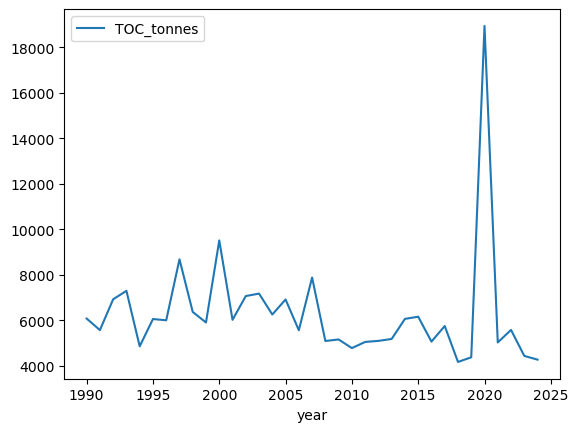

In [44]:
osp_df.loc[osp_df['station_code'].isin(['TROEMÅL', 'TROEMÅL2']), ['station_code', 'year', 'TOC_tonnes']].set_index('year').plot()

In [45]:
# For målselva:

# Set code as just TROEMÅL2 for resa3 areal export
resa_annual_df.loc[resa_annual_df['station_code'] == 'TROEMÅL', 'station_code'] = 'TROEMÅL2'

# # Check
# resa_annual_df.loc[
#     (resa_annual_df['variable'] == 'TOC_kg/km2')
#     & (resa_annual_df['station_code'].isin(['TROEMÅL', 'TROEMÅL2']))
# ]

# Drop TROEMÅL altogether from ospar (keep only TROEMÅL2)
osp_df = osp_df.loc[
    osp_df["station_code"] != "TROEMÅL"
].copy()

In [46]:
# Catchment area lookup
area_lookup = (
    resa_catchs_gdf[
        ["resa_station_code", "vm_area_km2"]
    ]
    .drop_duplicates()
    .rename(columns={"resa_station_code": "station_code"})
)

# Add area to RESA
resa_cmp = resa_annual_df.merge(
    area_lookup,
    on="station_code",
    how="left"
)

# TOC only for now
resa_cmp = resa_cmp.loc[
    resa_cmp["variable"] == "TOC_kg/km2"
].copy()

resa_cmp["flux_tonnes"] = (
    resa_cmp["annual_flux"]
    * resa_cmp["vm_area_km2"]
    / 1000
)

# For Ospar:
osp_cmp = osp_df.merge(
    area_lookup,
    on="station_code",
    how="left"
)

osp_cmp["flux_kgkm2"] = (
    osp_cmp["TOC_tonnes"]
    * 1000
    / osp_cmp["vm_area_km2"]
)

# ---------
# Check site codes are going to match
common_ids = np.intersect1d(
    area_lookup["station_code"].unique(),
    osp_df["station_code"].unique()
)

print("Number of rivs in Ospar fluxes:", len(osp_df["station_code"].unique()))
print(f"Common IDs: {len(common_ids)}")
print("Common IDs:", common_ids)

# --------------------
# Construct a table to compare the two
compare_df = (
    resa_cmp[
        ["station_code", "year", "annual_flux", "flux_tonnes"]
    ]
    .rename(
        columns={
            "annual_flux": "resa_kgkm2",
            "flux_tonnes": "resa_tonnes"
        }
    )
    .merge(
        osp_cmp[
            ["station_code", "year", "flux_kgkm2", "TOC_tonnes"]
        ].rename(
            columns={
                "flux_kgkm2": "osp_kgkm2",
                "TOC_tonnes": "osp_tonnes"
            }
        ),
        on=["station_code", "year"],
        how="inner"
    )
)

Number of rivs in Ospar fluxes: 20
Common IDs: 20
Common IDs: ['AAGEVEG' 'BUSEDRA' 'FINEALT' 'FINEPAS' 'FINETAN' 'HOREVOS' 'MROEDRI'
 'NOREVEF' 'OSLEALN' 'ROGEBJE' 'ROGEORR' 'ROGEVIK' 'SFJENAU' 'STRENID'
 'STREORK' 'TELESKI' 'TROEMÅL2' 'VAGEOTR' 'VESENUM' 'ØSTEGLO']


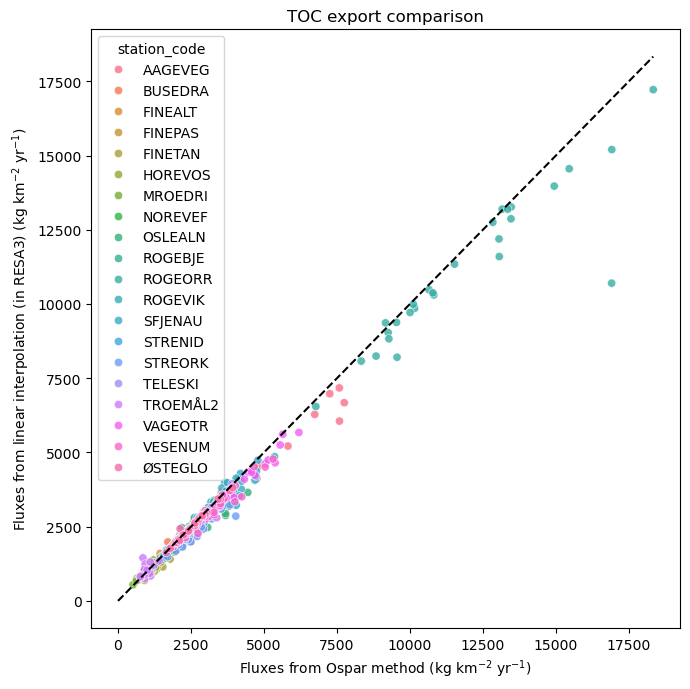

In [82]:
# Plot of overall agreement
fig, ax = plt.subplots(figsize=(7,7))

sns.scatterplot(
    data=compare_df,
    x="osp_kgkm2",
    y="resa_kgkm2",
    hue="station_code",
    alpha=0.8
)

lims = [
    0,
    max(
        compare_df["osp_kgkm2"].max(),
        compare_df["resa_kgkm2"].max()
    )
]

ax.plot(lims, lims, "k--")

ax.set_xlabel("Fluxes from Ospar method (kg km$^{-2}$ yr$^{-1}$)")
ax.set_ylabel("Fluxes from linear interpolation (in RESA3) (kg km$^{-2}$ yr$^{-1}$)")
ax.set_title("TOC export comparison")

plt.savefig(os.path.join(out_folder, 'figures', 'annual_fluxes_linear_interp_vs_ospar_scatter.png'))

plt.tight_layout()

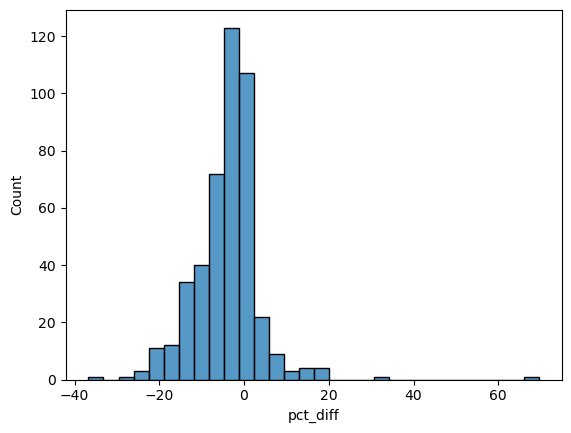

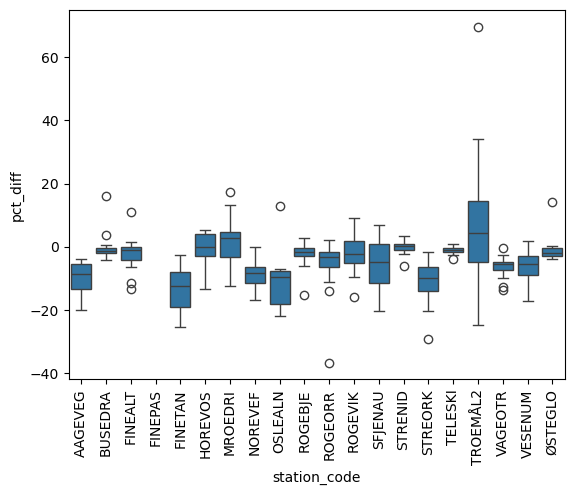

In [48]:
compare_df["pct_diff"] = (
    100
    * (compare_df["resa_kgkm2"] - compare_df["osp_kgkm2"])
    / compare_df["osp_kgkm2"]
)

sns.histplot(compare_df["pct_diff"], bins=30)
plt.show()

sns.boxplot(
    data=compare_df,
    x="station_code",
    y="pct_diff"
)
plt.xticks(rotation=90)
plt.show()

In [49]:
compare_df.head()

,station_code,year,resa_kgkm2,resa_tonnes,osp_kgkm2,osp_tonnes,pct_diff
0,AAGEVEG,2017,6675.403491,2710.667012,7750.160640,3147.091380,-13.867547
1,AAGEVEG,2018,4546.543629,1846.205379,4810.906456,1953.554634,-5.495073
2,AAGEVEG,2019,7173.903716,2913.091946,7580.466743,3078.184137,-5.363298
3,AAGEVEG,2020,6281.130954,2550.565595,6738.315976,2736.213752,-6.784856
4,AAGEVEG,2021,4120.311591,1673.126235,4756.422069,1931.430275,-13.373718


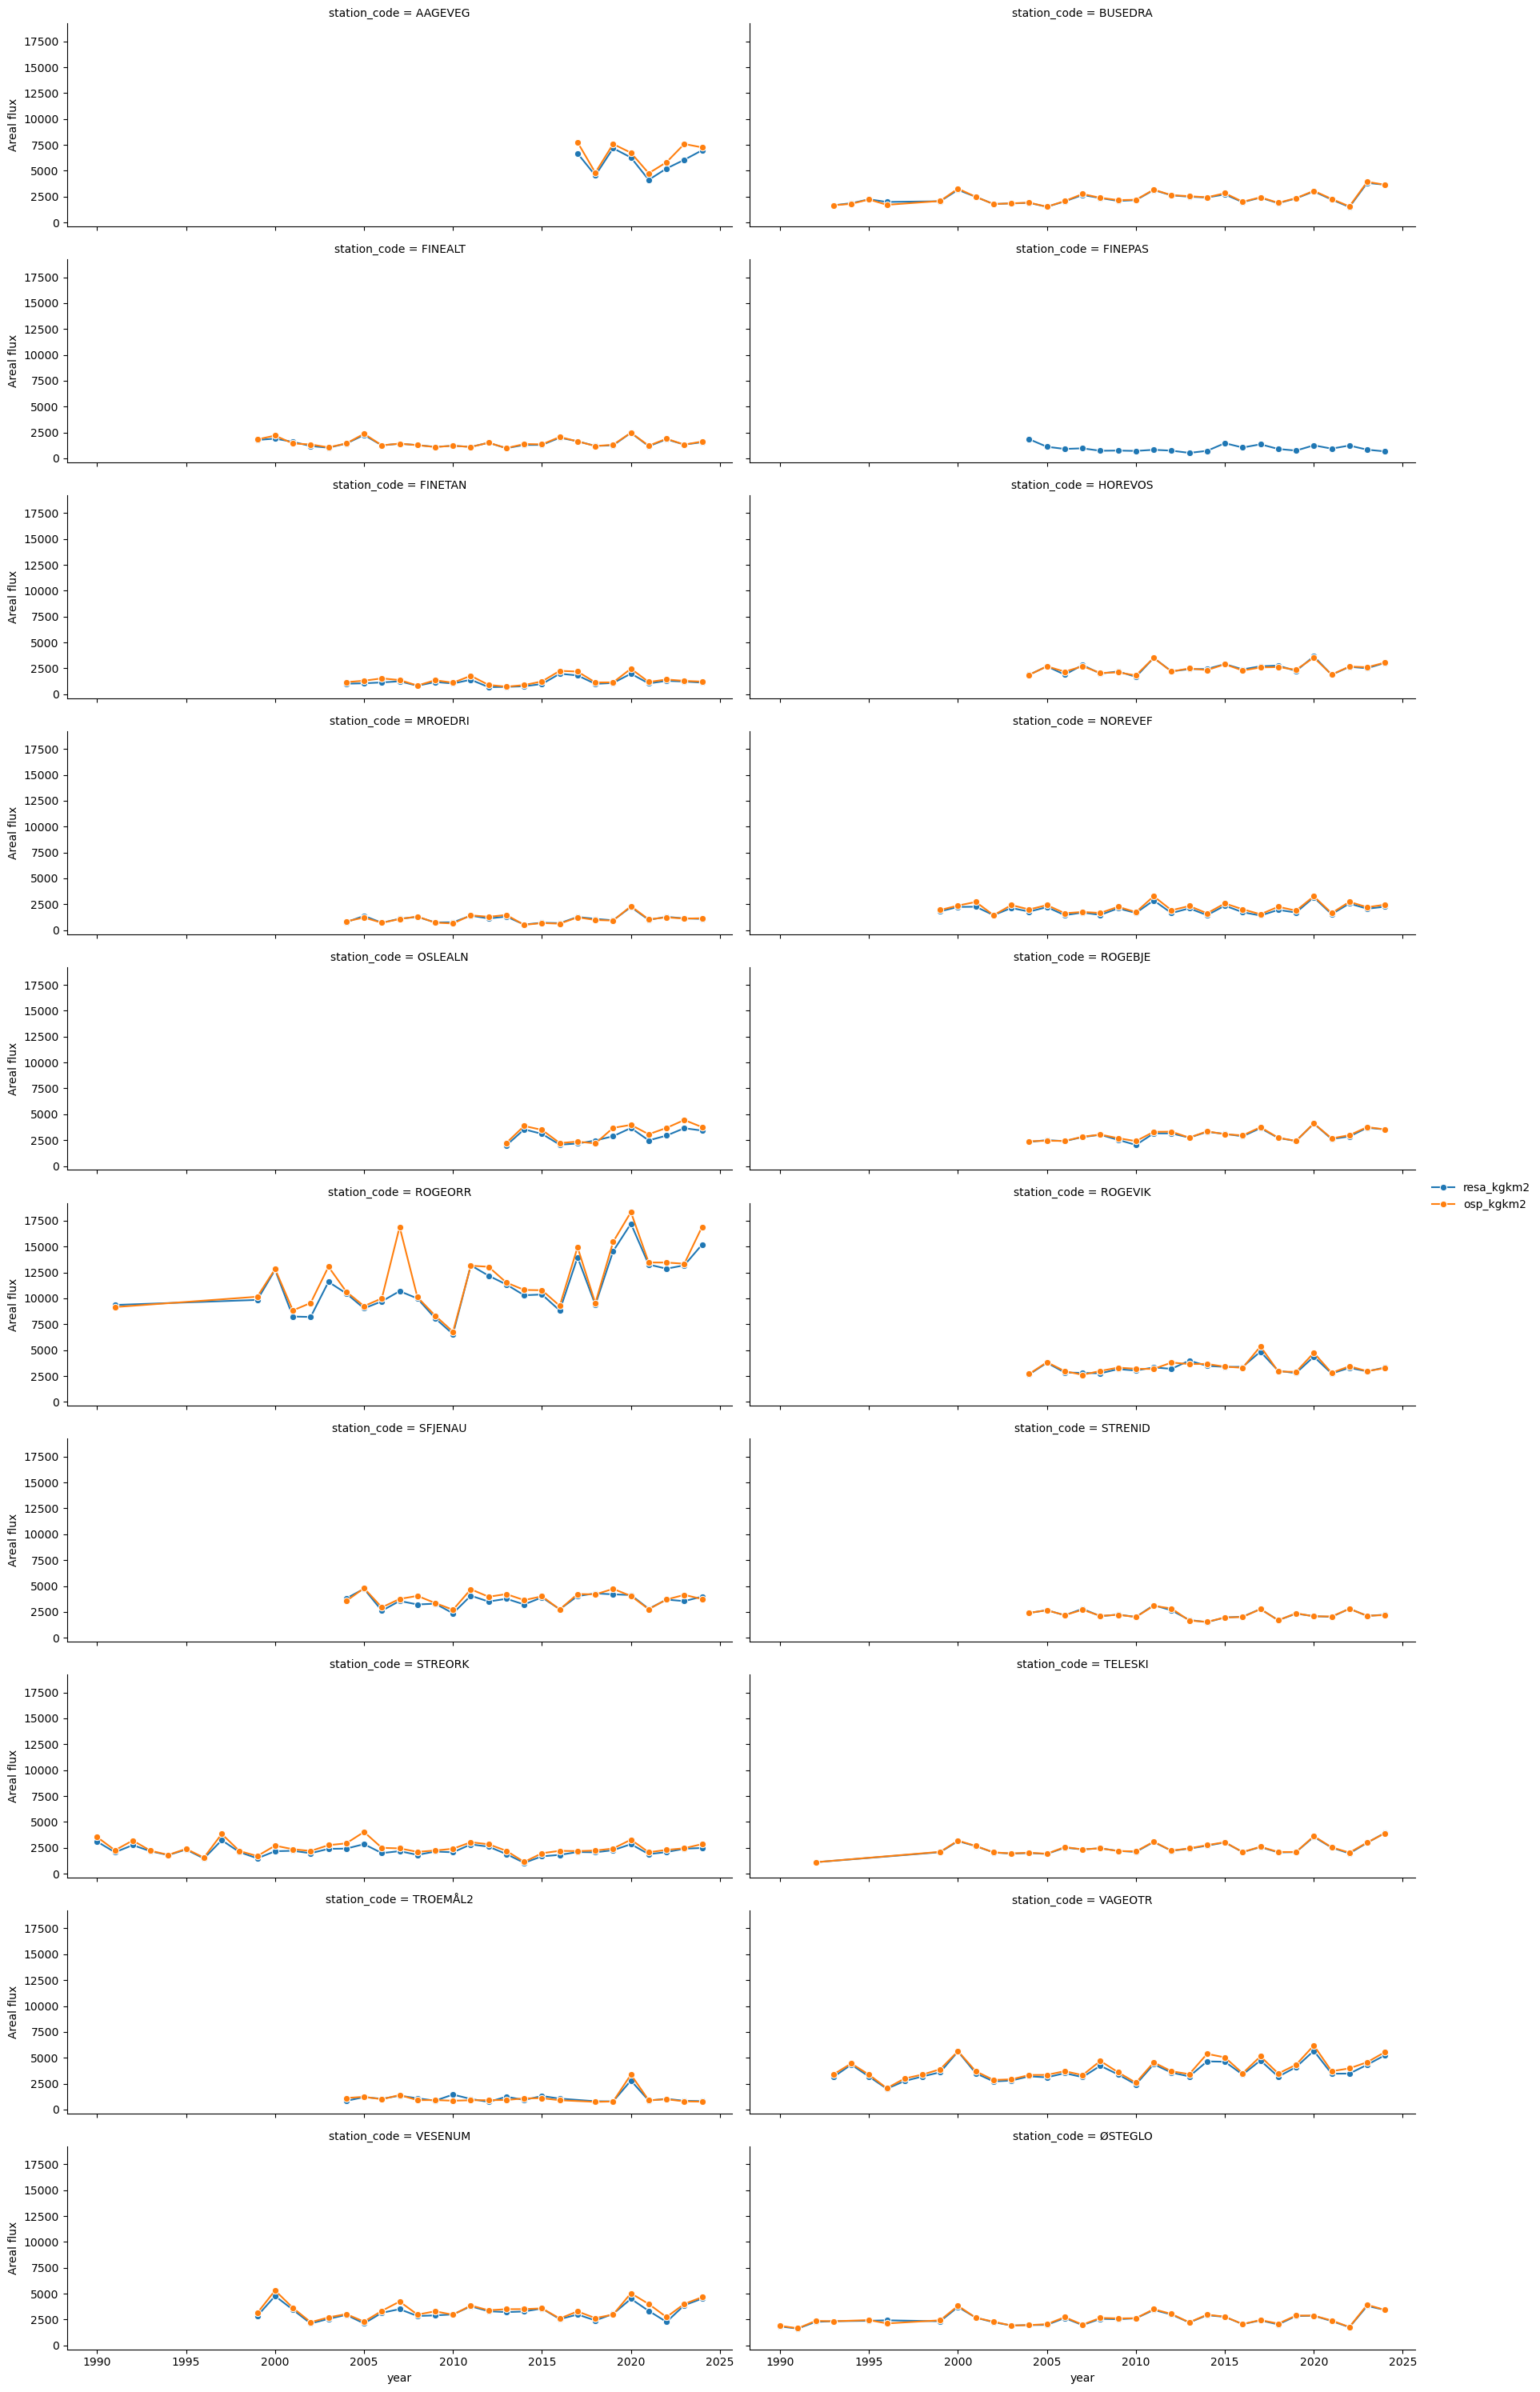

In [81]:
# Annual time series per station with data from both methods
plot_df = (
    compare_df
    .melt(
        id_vars=["station_code", "year"],
        value_vars=["resa_kgkm2", "osp_kgkm2"],
        var_name="source",
        value_name="Areal flux"
    )
)

g = sns.FacetGrid(
    plot_df,
    col="station_code",
    col_wrap=2,
    sharey=True,
    height=3,
    aspect=3
)

g.map_dataframe(
    sns.lineplot,
    x="year",
    y="Areal flux",
    hue="source",
    marker="o"
)

g.add_legend()

plt.savefig(os.path.join(out_folder, 'figures', 'annual_fluxes_linear_interp_vs_ospar_timeseries.png'))
plt.show()

## Average across years

In [83]:
# RESA export
years_per_station = (
    resa_cmp.groupby("station_code")["year"]
    .apply(set)
)

common_years = sorted(
    set.intersection(*years_per_station)
)

print(common_years)

[]


In [85]:
# Coverage by year
coverage = (
    resa_cmp.groupby("year")["station_code"]
    .nunique()
    .sort_index()
)

print(coverage)

year
1990     2
1991     3
1992     3
1993     4
1994     3
1995     4
1996     4
1997     2
1998     2
1999     9
2000     9
2001     9
2002     9
2003     9
2004    45
2005    45
2006    45
2007    45
2008    45
2009    45
2010    45
2011    45
2012    45
2013    46
2014    46
2015    46
2016    46
2017    19
2018    20
2019    20
2020    20
2021    20
2022    20
2023    20
2024    20
Name: station_code, dtype: int64


In [84]:
resa_cmp.head()

,station_code,year,variable,annual_flux,vm_area_km2,flux_tonnes
3616,AAGENID,2004,TOC_kg/km2,2436.299794,3937.025428,9591.774237
3617,AAGENID,2005,TOC_kg/km2,1600.860731,3937.025428,6302.629404
3618,AAGENID,2006,TOC_kg/km2,3444.961377,3937.025428,13562.900537
3619,AAGENID,2007,TOC_kg/km2,2014.535136,3937.025428,7931.276057
3620,AAGENID,2008,TOC_kg/km2,3659.890764,3937.025428,14409.083001


# Make map

In [51]:
# Aggregate across all available years
map_df = (
    resa_cmp
    .groupby("station_code", as_index=False)
    .agg(mean_export=("annual_flux", "mean"))
)

# Join to catchments
map_gdf = resa_catchs_gdf.merge(
    map_df,
    left_on="resa_station_code",
    right_on="station_code",
    how="left"
)

map_gdf.head(3)

,resa_station_id,resa_station_code,resa_station_name,resa_Latitude,resa_Longitude,lat_r,lon_r,vm_site_code,vm_lon,vm_lat,...,vm_Name,vm_start_year,vm_end_year,vm_n_years,vm_n_samples,vm_av_freq,vm_area_km2,geometry,station_code,mean_export
0,40352,BUSEDRA,Drammenselva,59.752576,10.007898,59.8,10.0,012-38512,10.009034,59.753432,...,Drammenselva ved Mjøndalen bru,1991.0,2025.0,34.0,569.0,16.73,16963.072067,"POLYGON ((176380 6708620, 176380 6708760, 1763...",BUSEDRA,2330.770696
1,40353,TELESKI,Skienselva,59.203230,9.606396,59.2,9.6,016-38513,9.611355,59.198078,...,Skienselva ved Klosterfossen,1991.0,2024.0,33.1,318.0,9.60,10674.740281,"POLYGON ((77300 6616140, 77280 6616140, 77280 ...",TELESKI,2432.820800
2,40354,VAGEOTR,Otra,58.184772,7.958165,58.2,8.0,021-38514,7.952947,58.186669,...,Otra ved Skråstad (VK1),1991.0,2025.0,34.1,582.0,17.05,3599.019104,"POLYGON ((73320 6550880, 73320 6550900, 73340 ...",VAGEOTR,3685.447152


In [58]:
spatial_dir = "/home/jovyan/shared/common/norsink/spatial/coastal_drainage_basins"
bbox_gdf = gpd.read_file(os.path.join(spatial_dir, "shp", "bounding_box.shp"))
sea_gdf = gpd.read_file(os.path.join(spatial_dir, "shp", "sea.shp"))
# riv_gdf = gpd.read_file(os.path.join(spatial_dir, "shp", "rivers.shp"))
# outlet_gdf = gpd.read_file(os.path.join(cur_dir, "shp", "outlets_all.shp"))

In [75]:
# Create outlet points from lon/lat
outlets_gdf = gpd.GeoDataFrame(
    map_gdf[["station_code", "vm_lon", "vm_lat"]].copy(),
    geometry=gpd.points_from_xy(
        map_gdf["vm_lon"],
        map_gdf["vm_lat"]
    ),
    crs="EPSG:4326",  # assuming lon/lat are WGS84
)

# Reproject to match catchment CRS
outlets_gdf = outlets_gdf.to_crs(map_gdf.crs)

In [66]:
map_gdf.describe()

,resa_station_id,resa_Latitude,resa_Longitude,lat_r,lon_r,vm_lon,vm_lat,vm_site_id,vm_start_year,vm_end_year,vm_n_years,vm_n_samples,vm_av_freq,vm_area_km2,mean_export
count,48.000000,48.000000,48.000000,48.00000,48.000000,47.000000,47.000000,47.000000,47.000000,47.000000,47.000000,47.000000,47.000000,47.000000,47.000000
mean,41438.333333,61.991523,10.555412,61.98750,10.556250,10.140929,61.839871,41244.021277,2000.744681,2021.042553,20.882979,230.106383,10.213617,3634.260212,2974.727224
std,5207.151079,3.769115,5.577403,3.76126,5.578489,4.823568,3.639339,11300.253851,8.052729,4.373624,10.140177,315.569687,9.206578,6701.192237,1752.280541
min,40352.000000,58.143109,5.529975,58.10000,5.500000,5.525528,58.143145,27996.000000,1984.000000,2007.000000,3.500000,16.000000,2.770000,64.422503,972.398489
25%,40364.750000,59.011743,6.605241,59.05000,6.625000,6.551681,58.964687,38524.500000,1993.500000,2017.000000,12.600000,50.500000,4.145000,595.506504,1941.148736
50%,40376.500000,61.008285,9.167490,61.00000,9.200000,8.980148,60.647051,38537.000000,2004.000000,2024.000000,20.500000,88.000000,9.240000,1573.743139,2749.572509
75%,40388.250000,63.833552,11.524846,63.85000,11.525000,11.459397,63.620055,38549.500000,2004.000000,2024.000000,31.000000,259.500000,11.980000,3683.373296,3416.743835
max,69594.000000,70.229848,30.110084,70.20000,30.100000,28.169086,70.229681,90047.000000,2019.000000,2025.000000,41.900000,1638.000000,52.880000,41688.901865,11127.868947


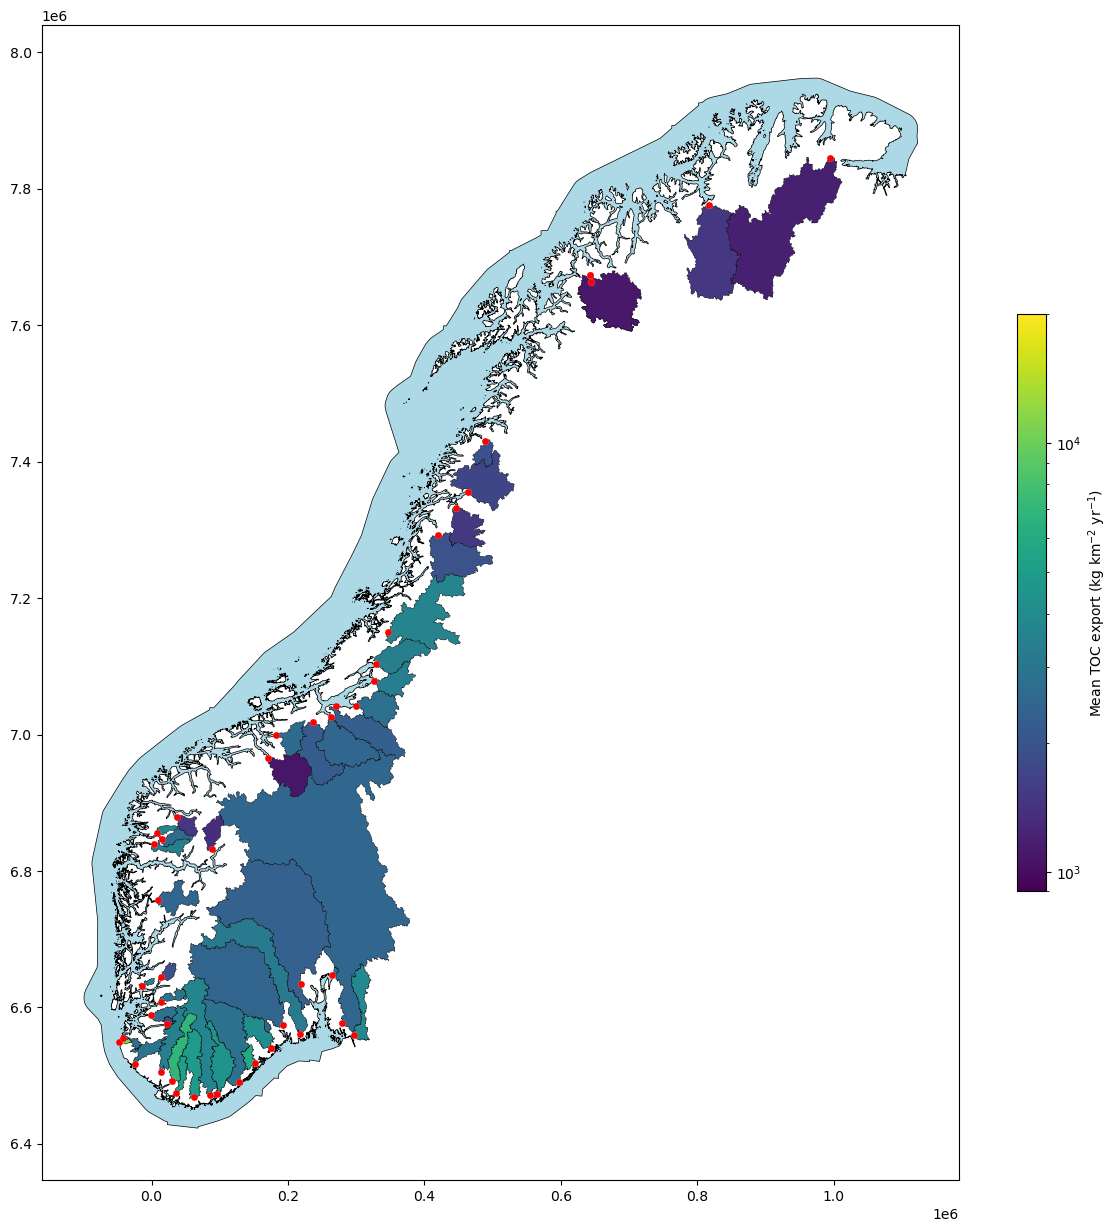

In [79]:
from matplotlib.colors import LogNorm
import matplotlib.ticker as mticker

fig, ax = plt.subplots(figsize=(15, 15))

sea_gdf.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="k",
    lw=0.5,
)

# Catchments with areal fluxes
map_gdf.plot(
    ax=ax,
    column="mean_export",
    cmap="viridis",
    norm=LogNorm(vmin=900, vmax=20000),
    legend=True,
    legend_kwds={
        "label": "Mean TOC export (kg km$^{-2}$ yr$^{-1}$)",
        "shrink": 0.5,  # make colourbar shorter
    },
    edgecolor="black",
    linewidth=0.2,
)

# Outlets
outlets_gdf.plot(
    ax=ax,
    color="red",
    edgecolor="white",
    linewidth=0.1,
    markersize=25,
    zorder=10,
)

# # Try labels
# for x, y, label in zip(
#     outlets_gdf.geometry.x,
#     outlets_gdf.geometry.y,
#     outlets_gdf["station_code"]
# ):
#     ax.annotate(
#         label,
#         (x, y),
#         fontsize=6,
#         xytext=(3, 3),
#         textcoords="offset points",
#     )

plt.savefig(os.path.join(out_folder, 'figures', 'resa_areal_export_map.png'))
plt.show()